<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/02_geodataframe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.2 Estructuras de datos en GeoPandas (resumen)

Resumen del capítulo *Introduction to data structures in geopandas* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG.

El libro usa datos de Austin y Helsinki. Aquí se usan **las farmacias de Asturias** (`raw/farmacias_botiquines__farmacias_*.geojson`), así que el código funciona con tus datos.

**Ideas clave**
- Un `GeoDataFrame` es un `DataFrame` de pandas con una columna de geometrías (`geometry`). Todo lo de pandas sigue funcionando: filtrar, agrupar y crear columnas.
- Esa columna es una `GeoSeries`: cada celda es un objeto `shapely` (`Point`, `Polygon`…). Los métodos de shapely (`area`, `buffer`, `distance`…) se aplican **a la columna entera** de una vez.
- El `GeoDataFrame` guarda el **CRS**, cosa que la geometría `shapely` sola no hace.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

DATA_DIR = Path("/content/drive/MyDrive/tfg/sitpa_raw_data/")

pharmacies_fp = sorted(DATA_DIR.glob("farmacias_botiquines__farmacias_*.geojson"))[-1]  # latest download

## Leer un fichero

`gpd.read_file()` lee cualquier formato vectorial habitual (GeoPackage, GeoJSON, Shapefile, KML…). El formato se deduce de la extensión.

In [3]:
pharmacies = gpd.read_file(pharmacies_fp)

print(type(pharmacies))
print(pharmacies.crs, "|", len(pharmacies), "rows")
pharmacies[["titular", "poblacion", "concejo", "geometry"]].head(3)

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326 | 454 rows


,titular,poblacion,concejo,geometry
0,ALBA FERNANDEZ RODRIGUEZ,AVILES,AVILES,POINT (-5.92225 43.55586)
1,ANA COVADONGA PARIS GRAIÑO,AVILES,AVILES,POINT (-5.9232 43.55717)
2,JUAN RODRIGUEZ DE LA FLOR MORO,AVILES,AVILES,POINT (-5.92245 43.55577)


Lo primero con una capa nueva: ver el CRS, el número de filas y el tipo de geometría. Aquí el CRS es EPSG:4326 (grados), así que **antes de medir hay que reproyectar** a EPSG:25830. Eso es el ejercicio 1 de `gis_exercises.ipynb` y el siguiente capítulo del libro.

Point    454
Name: count, dtype: int64


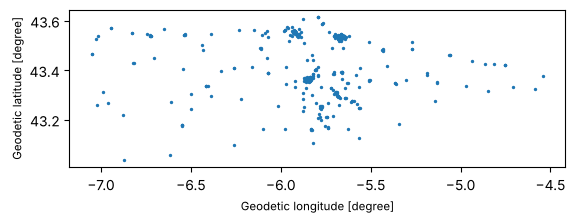

In [ ]:
print(pharmacies.geom_type.value_counts())
pharmacies.plot(markersize=2);  # quick visual check, the cloud of points should have the shape of Asturias

## La columna de geometría

`gdf.geometry` devuelve la `GeoSeries` activa, con `dtype` `geometry`. Las propiedades de shapely funcionan sobre toda la columna, sin bucles.

In [ ]:
print(type(pharmacies.geometry))
print(pharmacies.geometry.x.head(3))  # longitude of every point (vectorised)

<class 'geopandas.geoseries.GeoSeries'>
0   -5.922250
1   -5.923203
2   -5.922451
dtype: float64


Lo mismo vale para `.area`, `.length`, `.centroid`, `.buffer(d)` o `.distance(geom)`: devuelven una `Series`/`GeoSeries` con un valor por fila, **en las unidades del CRS**.

Las operaciones de pandas siguen igual. Por ejemplo, contar farmacias por concejo:

In [ ]:
pharmacies["concejo"].value_counts().head(5)

concejo
GIJON      104
OVIEDO      90
AVILES      37
MIERES      24
LANGREO     23
Name: count, dtype: int64

## Escribir un fichero

`gdf.to_file(path)` deduce el formato de la extensión. **Sobrescribe sin avisar** si el fichero ya existe.

En el TFG se usa GeoPackage (`.gpkg`): un solo fichero que guarda el CRS y admite varias capas (`layer=`).

In [ ]:
import tempfile

out_fp = Path(tempfile.gettempdir()) / "pharmacies_test.gpkg"  # temp dir so the project folder stays clean
pharmacies.to_file(out_fp, layer="pharmacies")

check = gpd.read_file(out_fp, layer="pharmacies")
print(len(check), check.crs)  # same rows and CRS as the original

454 EPSG:4326


## Crear un GeoDataFrame a partir de coordenadas

Es el caso típico de una tabla (CSV, Excel, JSON) con columnas de longitud y latitud. `gpd.points_from_xy(x, y)` crea los `Point`. **x = longitud, y = latitud.**

⚠️ El libro crea el `GeoDataFrame` sin CRS. Indícalo siempre (`crs=`). Si no lo haces, GeoPandas no sabe qué significan los números y `to_crs` falla.

In [ ]:
# Toy table: two settlements with lon/lat
settlements = pd.DataFrame({
    "name": ["Grado", "Cangas del Narcea"],
    "lon": [-6.0711, -6.5544],
    "lat": [43.3883, 43.1771],
})

settlements_gdf = gpd.GeoDataFrame(
    settlements,
    geometry=gpd.points_from_xy(settlements["lon"], settlements["lat"]),
    crs="EPSG:4326",
)
settlements_gdf

,name,lon,lat,geometry
0,Grado,-6.0711,43.3883,POINT (-6.0711 43.3883)
1,Cangas del Narcea,-6.5544,43.1771,POINT (-6.5544 43.1771)


Para una sola geometría construida a mano: `gpd.GeoDataFrame({"name": ["x"]}, geometry=[polygon], crs=...)`.

## Lo que se ha omitido del capítulo
- **Otros formatos** (Shapefile, KML, MapInfo, FileGDB, FlatGeobuf): misma sintaxis, solo cambia la extensión o `driver=`. `pyogrio.list_drivers()` lista los soportados.
- **Leer de un ZIP**: `gpd.read_file("archivo.zip!carpeta/capa.shp")`. El `!` separa el ZIP de la ruta interna. Te servirá para `Centros_EdPrimaria_2022.zip`, que contiene un Shapefile.
- **Mapas coloreados** por una columna: `gdf.plot(column="col")`. Se ven en el capítulo 8.
- **Varias columnas de geometría** y cambio de geometría activa: no hace falta en el TFG.

Documentación: https://geopandas.org/en/stable/docs/user_guide/data_structures.html